## Predicing Asset Price Direction

In [7]:
from PIL import Image 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import statsmodels.api as sm

### Asset Pricing Theory

Theory There is a misconception about the naming and purpose. APT is not concerned with price prediction but the 'pricing' in relation to the market benchmark (S&P 500 index). APT concerns itself estimation of beta(s) estimating of beta, which is relation between asset returns and the market. First, if we know the beta, we know where we are on in relation to markets. Second, beta estimation can be made more robust than daily returns.

### Improving on price information

To organise the prediction we start with features: generate 7-10 price-related features (columns) and run Classifier.fit() on them. For each classifier, you can produce ROC, Confusion Matrix, Transition Probabilities -- the startard metrics of supervised learning.
This demo derives features (lagged returns) from the asset price. There is large discussion about how much information is present in stock prices vs. other data, such as fundamentals, macro economic, and alternative data.
However, the forecasting can be technically improved by using the measures of Average and Momentum. You will need to make reasonable choices of time period (rolling window) for SMA, EMA, Momentum. This link, gives one example on how to do Exponential Moving Average from the first principles. The choice of smoothing factor  

$ \alpha = \frac{2}{N_{obs} +1} $


### Binomial or Multinomial?

Setting up prediction classes, you are likely to encounter the high count of uncertain moves/'no move', where the movement took less than 1/10th of a percentage point.
Remember that for a global market index, the daily average return can be  O(0.004%) , [-1,0,1]trinomial classification might be more appropriate, but there is no trading action that follows from the prediction of no move in the asset.

One but not a universal approach, is to label 'no moves' as positive moves. That keeps continuity because most of the moves are positive and we are interested in:
- isolating information carried by empirical negative returns;
- better quality in negative market moves prediction.

Because of the asymmetry of reward for losing money (which one wants to avoid and associated with worse feelings), as compared to gaining money.

Simply dropping 'no move' observations will be detrimental in such sensitive tasks as daily predition.

### Not Least Squares

This demo is NOT about autoregression analysis in itself. Autoregression is the application of regression on past returns. The regression is essentially an application a linear model and the method of computation (Maximum Likelihood) involves "the Ordinary Least Squares",  
$ \epsilon_t^2 = (y_t -\beta  x_t)^2 $
, hence the abbreviation OLS.
If you formally attempt to use the autogression (or vector autoregression for multiple tickers at the same time) in order to predict the daily return quantity -- you will encounter the forecasting error of  150−200%

Example: you are predicting return of -1.5%, the order of error above means that realised return will be anything up to +1.5%, eg 3% absolute difference.


OLS is NOT a valid regression model for binary dependent variable  0,1 or for  $y_t,x_t$ any other than Normal variables. There is no inherent model risk when OLS is applied to quarterly changes in such variables as GDP and economic macro -- that is a valid forecasting move. However, OLS does fail at predicing financial asset daily returns (eg, error of  150−200 %) and is certainly methodologically wrong to use on non-stationary, stochastic prices  $S_t$. Think about it: when you are correlating and regressing prices of two assets, you simply regressing one Brownian Motion on another.
Change in the nature of dependent variable leads to the change in Maximum Likelhood -- which is 'under the hood' method of how regression works, how regression coefficients are derived and computed. We will consider that today.


**Genearalized Linear Models (GLM)** is both, extension and the substitution of the linear regression (OLS). It implies a non-linear **link function** between dependent variable, such as Binary  
0,1 and implied probability  
[0.01..0.99]. Logistic Regression (Classification) and its Maximum Likelihood is a good illustration and introduction to the GLM.
We will also demonstrate that prediction results (for asset price direction) that are coming from OLS linear regression are a fudge.

In [5]:
path = "C:/Admin/CQF Course/Python Labs/Data Source & Market Prediction/RELEASE/data/EquitiesDataGOOG.xlsx"
data = pd.read_excel(path, sheet_name = 'Sheet1', index_col=0, usecols = [0,5])
data.rename(columns = {'Adj Close':'Price'}, inplace = True)

In [8]:
data['Return'] = np.log(data['Price'].diff(periods =1))

for i in range(1,6):
    data['Return_{}'.format(i)] = data['Return'].shift(periods =i)

data['Return_Sign'] = np.sign(data['Return'])
data.dropna(inplace = True)
data_1 = data.copy(deep =True)


c:\Users\Prasoon Gupta\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


### Autocorrelation in Lagged Returns(log run)

In [9]:
corr = data_1.loc[:,['Return_1','Return_2','Return_3','Return_4','Return_5']].corr()

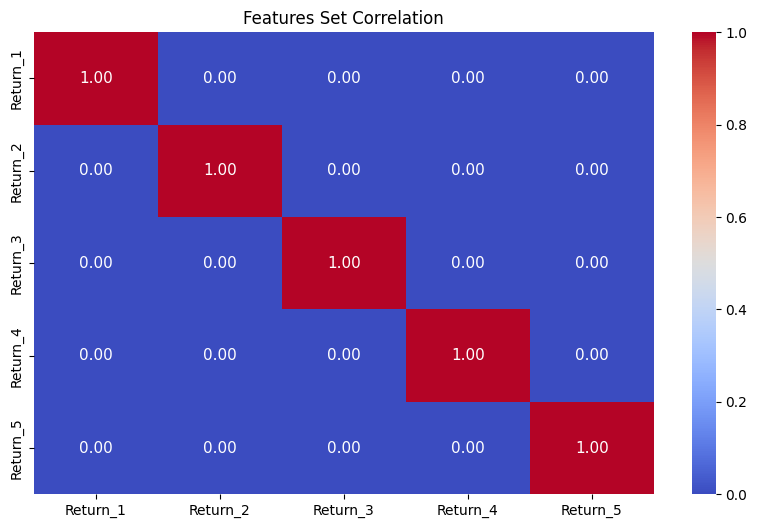

In [10]:
# remove all correlated features with threshold > 0.85

plt.figure(figsize =(10,6))
sns.heatmap(corr >0.85, annot = True, cmap = 'coolwarm',fmt = '0.2f', cbar = True,annot_kws = {'size':11})
plt.title('Features Set Correlation')
plt.show()

### Maximum Likelihood for Regression(Ordinary Least Squares)

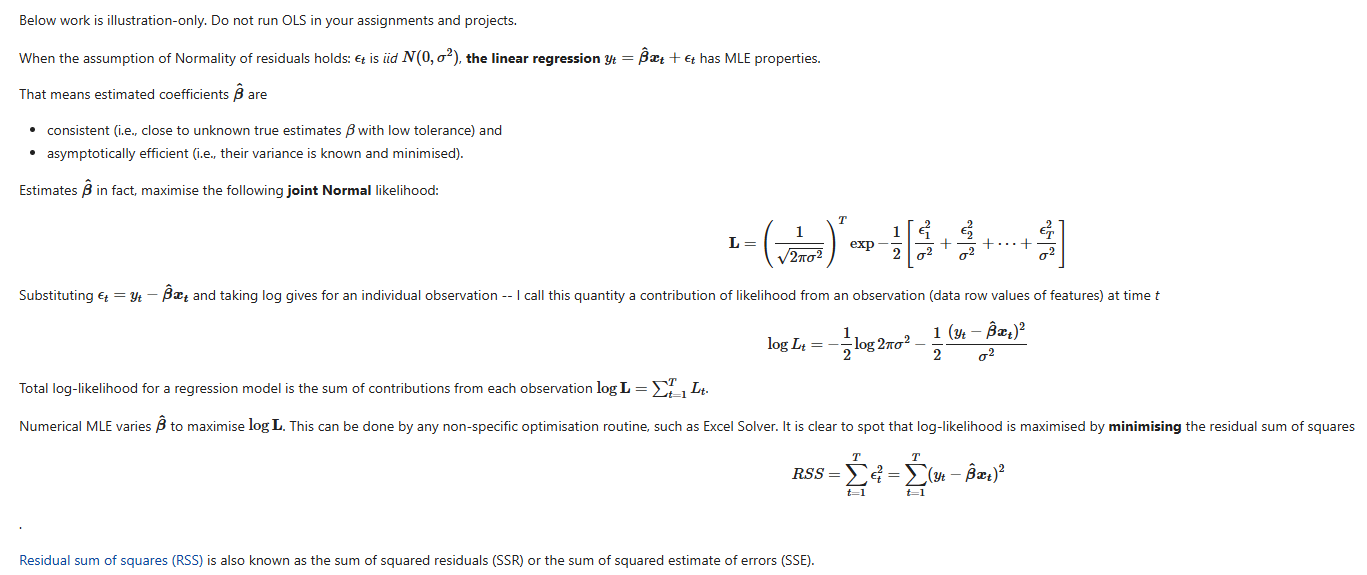

In [11]:
Image.open("C:/Admin/CQF Course/Python Labs/Data Source & Market Prediction/pic_1.PNG")

### Linear Regresion

In [12]:
# we are using 'statsmodels.api' package for linear regression

X = data_1[['Return_1','Return_2','Return_3','Return_4','Return_5']]
y = data_1['Return_Sign']
model = sm.OLS(endog=y, exog=X)
results = model.fit()
coef = np.array([results.params[0],results.params[1],results.params[2],results.params[3],results.params[4]])

C:\Users\Prasoon Gupta\AppData\Local\Temp\ipykernel_9820\4230290652.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coef = np.array([results.params[0],results.params[1],results.params[2],results.params[3],results.params[4]])


In [13]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            Return_Sign   R-squared (uncentered):                   0.455
Model:                            OLS   Adj. R-squared (uncentered):              0.370
Method:                 Least Squares   F-statistic:                              5.351
Date:                Mon, 21 Apr 2025   Prob (F-statistic):                     0.00110
Time:                        20:54:36   Log-Likelihood:                         -41.259
No. Observations:                  37   AIC:                                      92.52
Df Residuals:                      32   BIC:                                      100.6
Df Model:                           5                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Return_1       0.0218      0.117      0.186      0.854      -0.216       0.260
Return_2       0.1086      0.080      1.360      0.183      -0.054       0.271
Return_3       0.0639      0.082      0.779      0.442      -0.103       0.231
Return_4       0.3013      0.100      3.006      0.005       0.097       0.506
Return_5       0.0605      0.097      0.625      0.536      -0.137       0.257
==============================================================================
Omnibus:                        4.404   Durbin-Watson:                   2.087
Prob(Omnibus):                  0.111   Jarque-Bera (JB):                3.937
Skew:                          -0.794   Prob(JB):                        0.140
Kurtosis:                       2.826   Cond. No.                         2.57
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
data_1_array = data_1[['Return_1','Return_2','Return_3','Return_4','Return_5']].values
data_1['ols_pred'] = np.sign(data_1_array@coef[:,np.newaxis])
data_1['ols_pred_backtest'] = data_1['Return']*data_1['ols_pred']

### Vectorised Backtesting = Rebalancing

|'ols_pred'|'return'|Result P&L|
|:-|:-|:-|
|NEGATIVE 'ols_pred'|NEGTIVE 'return'|POSITIVE P&L|
|NEGATIVE 'ols_pred'|POSITIVE 'return' (move up)|NEGATIVE P&L, Loss|
|POSITIVE 'ols_pred'|NEGTIVE 'return'|NEGATIVE P&L, Loss|
|POSITIVE 'ols_pred'|POSITIVE 'return'(move up)|POSITIVE P&L|

The assumption is daily rebalancing (daily betting) +100% or -100% of the asset, rather than replication of the actual asset path (hold position).
So, the vectorised backtesting assumes/represents a sequence of daily bets, based on the sign (up/down move) predicted from past returns.


The actual return that realises today  t, is % P&L that one makes (loses) on the bet of $100, for example if return today is POSITIVE 0.018 and predcited sign was POSITIVE, then P&L is 1.18%.

$ Return_{pred} = Z*\sigma $

 
Assume we want to have more model-like prediction. Then, we will use standard deviation, which gives some measure of randomness.

- We use std dev from the dataset but that can be estimated from any prevoius holdout period/window. Such backtesting requires past data but not regular daily update of return -- the latter is historical backtesting.

- Z∗=±0.7 of the standard deviation translates into betting %70 of one sigma -- the Actual P&L which would still depend on actual return. But we can plot cumulative P&L from 'ols_pred_move' to see if matches with the asset path. It also is possible to do P&L Attribution test on such std dev model:


'ols_pred_move' is in effect, our **Theoretical P&L** 'return' is the **Actual P&L**


- Why z-score of  ±0.7 ? This is because empirical asset returns are not well-Normal and between  ±2 standard deviation, but their density/histogram is high-peak (high mode). If you standardise returns  
zt=(rt−μ)/σ the histogram of  zt will have bars within  ±0.7.

Instead of  ±0.7 and to provide negative outcomes, we can use simulated values of Random Normal  $\phi$ which can be positive or negative.


In [15]:
std_dev = data_1['Return'].std()
data_1['ols_pred_move'] = 0.7*std_dev*data_1['ols_pred']

### Remember OLS is an invalid regresion model for binary dependent variables {0,1} . dont run OLS in your ML assignments & projects